<center><h1>Bharadwaj_Sujendra Giri Prasad_HW5</h1></center>
<br>
<br>

Name: Sujendra Giri Prasad Bharadwaj
<br>
Github Username: sgbharad-2305
<br>
USC ID: 1296124475

## 1. Decision Trees as Interpretable Models

Import packages

In [15]:
# Basic imports. I kept all model-related imports here so the later cells stay readable.
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, _tree, export_text, plot_tree

# xgboost may not be installed everywhere, so I use it only when it is available.
try:
    from xgboost import XGBRegressor
except Exception:
    XGBRegressor = None

warnings.filterwarnings("ignore")
sns.set_theme(context="notebook", style="ticks")

SEED = 42
HERE = Path.cwd().resolve()
DATA_PATH = HERE.parent / "data" if HERE.name == "notebook" else HERE / "data"
FIVE_FOLD = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Small helper used below whenever a fitted model is evaluated on the held-out set.
def mse_on_test(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    return mean_squared_error(y_test, predictions)

### (a) Obtain Data

Get the Accute Inamations Data Set

In [16]:
# The diagnosis file does not include a header, so I name the columns manually.
ACUTE_SCHEMA = [
    "Temperature", "Nausea", "Lumbar", "Urine", "Micturition", "Urethra",
    "Inflammation", "Nephritis",
]

def read_acute_data(folder):
    # The decimal mark is a comma in this data file, and the file is encoded as UTF-16.
    return pd.read_csv(
        folder / "diagnosis.data",
        sep="\t",
        header=None,
        names=ACUTE_SCHEMA,
        encoding="utf-16",
        decimal=",",
    )

acute_raw = read_acute_data(DATA_PATH)

# Quick sanity check before modeling.
display(acute_raw.head())
display(pd.DataFrame({
    "rows": [acute_raw.shape[0]],
    "columns": [acute_raw.shape[1]],
    "missing_cells": [int(acute_raw.isna().sum().sum())],
}))

,Temperature,Nausea,Lumbar,Urine,Micturition,Urethra,Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


,rows,columns,missing_cells
0,120,8,0


### (b) Build a decision tree

|--- Temperature <= 37.95
|   |--- Urine <= 0.50
|   |   |--- class: 0
|   |--- Urine >  0.50
|   |   |--- class: 1
|--- Temperature >  37.95
|   |--- Lumbar <= 0.50
|   |   |--- class: 0
|   |--- Lumbar >  0.50
|   |   |--- Nausea <= 0.50
|   |   |   |--- class: 0
|   |   |--- Nausea >  0.50
|   |   |   |--- Urine <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Urine >  0.50
|   |   |   |   |--- class: 0

Training set accuracy: 1.000


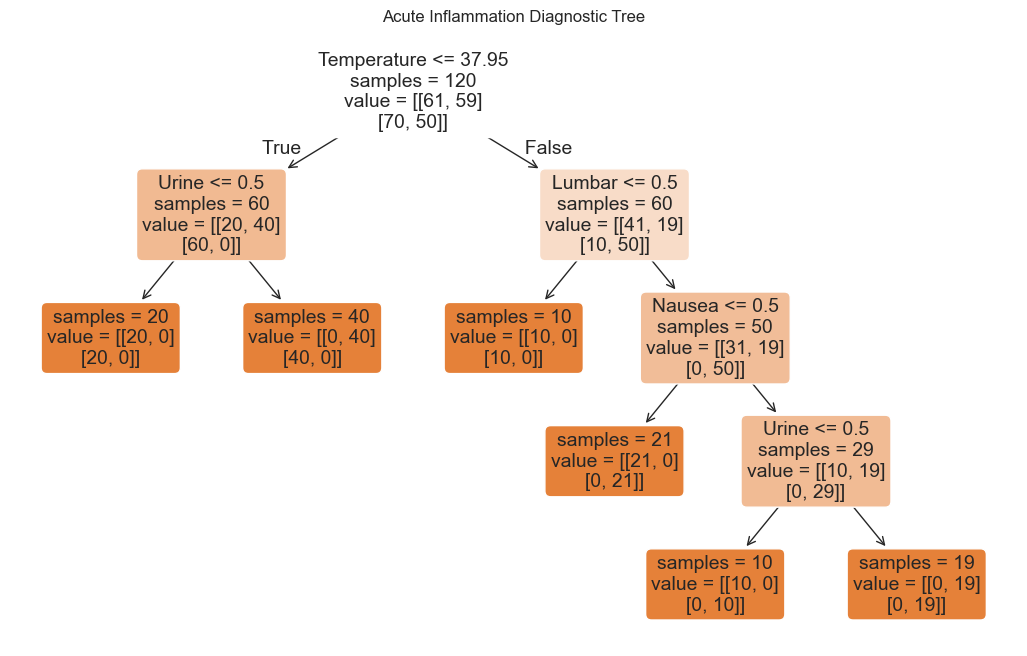

In [17]:
# Convert yes/no columns to 1/0. Temperature is already numeric.
diagnosis_targets = ["Inflammation", "Nephritis"]
symptom_columns = [column for column in acute_raw.columns if column not in diagnosis_targets]

acute_numeric = acute_raw.copy()
for column in acute_numeric.columns:
    if column != "Temperature":
        acute_numeric[column] = acute_numeric[column].map({"no": 0, "yes": 1})

X_acute = acute_numeric[symptom_columns]
y_acute = acute_numeric[diagnosis_targets]

# A full tree is easy to interpret here because the data is small and rule-like.
diagnosis_tree = DecisionTreeClassifier(random_state=SEED)
diagnosis_tree.fit(X_acute, y_acute)

print(export_text(diagnosis_tree, feature_names=symptom_columns))
print(f"Training set accuracy: {diagnosis_tree.score(X_acute, y_acute):.3f}")

fig, axis = plt.subplots(figsize=(13, 8))
plot_tree(
    diagnosis_tree,
    feature_names=symptom_columns,
    filled=True,
    rounded=True,
    impurity=False,
    ax=axis,
)
axis.set_title("Acute Inflammation Diagnostic Tree")
plt.show()

### (c) Convert the decision rules

In [18]:
def leaf_table(model, feature_names, output_names):
    """Turn terminal tree nodes into a small rule table."""
    rows = []
    stack = [(0, [])]
    fitted_tree = model.tree_

    # Walk through the tree by hand so the rules are shown as conditions + predictions.
    while stack:
        node, clauses = stack.pop()
        split_feature = fitted_tree.feature[node]

        if split_feature == _tree.TREE_UNDEFINED:
            prediction = {}
            for output_index, output_name in enumerate(output_names):
                class_labels = model.classes_[output_index]
                leaf_counts = fitted_tree.value[node][output_index]
                prediction[output_name] = int(class_labels[np.argmax(leaf_counts)])
            rows.append({"conditions": " and ".join(clauses) or "all records", **prediction})
            continue

        feature = feature_names[split_feature]
        threshold = fitted_tree.threshold[node]

        # Right branch is pushed first so the left branch appears first in the table.
        stack.append((fitted_tree.children_right[node], clauses + [f"{feature} > {threshold:.2f}"]))
        stack.append((fitted_tree.children_left[node], clauses + [f"{feature} <= {threshold:.2f}"]))

    return pd.DataFrame(rows)

# This is the handier version of the rules for explaining the tree.
display(leaf_table(diagnosis_tree, symptom_columns, diagnosis_targets))

# Compare pruning candidates. I choose the simplest tree among the best-accuracy trees.
pruning_rows = []
for alpha in diagnosis_tree.cost_complexity_pruning_path(X_acute, y_acute).ccp_alphas:
    candidate = DecisionTreeClassifier(random_state=SEED, ccp_alpha=alpha)
    candidate.fit(X_acute, y_acute)
    pruning_rows.append({
        "alpha": alpha,
        "accuracy": candidate.score(X_acute, y_acute),
        "leaves": candidate.get_n_leaves(),
        "depth": candidate.get_depth(),
        "model": candidate,
    })

pruning_table = pd.DataFrame(pruning_rows)
display(pruning_table.drop(columns="model"))

best_accuracy = pruning_table["accuracy"].max()
best_index = (
    pruning_table[pruning_table["accuracy"] == best_accuracy]
    .sort_values(["leaves", "depth", "alpha"], ascending=[True, True, False])
    .index[0]
)
pruned_tree = pruning_table.loc[best_index, "model"]

print("Selected compact tree")
print(f"alpha={pruning_table.loc[best_index, 'alpha']:.6f}, "
      f"accuracy={pruning_table.loc[best_index, 'accuracy']:.3f}, "
      f"leaves={int(pruning_table.loc[best_index, 'leaves'])}")
print(export_text(pruned_tree, feature_names=symptom_columns))
display(leaf_table(pruned_tree, symptom_columns, diagnosis_targets))

,conditions,Inflammation,Nephritis
0,Temperature <= 37.95 and Urine <= 0.50,0,0
1,Temperature <= 37.95 and Urine > 0.50,1,0
2,Temperature > 37.95 and Lumbar <= 0.50,0,0
3,Temperature > 37.95 and Lumbar > 0.50 and Naus...,0,1
4,Temperature > 37.95 and Lumbar > 0.50 and Naus...,0,1
5,Temperature > 37.95 and Lumbar > 0.50 and Naus...,1,1


,alpha,accuracy,leaves,depth
0,0.000000,1.000000,6,4
1,0.049083,0.841667,4,2
2,0.079472,0.758333,3,2
3,0.111111,0.591667,2,1
4,0.204236,0.250000,1,0


Selected compact tree
alpha=0.000000, accuracy=1.000, leaves=6
|--- Temperature <= 37.95
|   |--- Urine <= 0.50
|   |   |--- class: 0
|   |--- Urine >  0.50
|   |   |--- class: 1
|--- Temperature >  37.95
|   |--- Lumbar <= 0.50
|   |   |--- class: 0
|   |--- Lumbar >  0.50
|   |   |--- Nausea <= 0.50
|   |   |   |--- class: 0
|   |   |--- Nausea >  0.50
|   |   |   |--- Urine <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Urine >  0.50
|   |   |   |   |--- class: 0



,conditions,Inflammation,Nephritis
0,Temperature <= 37.95 and Urine <= 0.50,0,0
1,Temperature <= 37.95 and Urine > 0.50,1,0
2,Temperature > 37.95 and Lumbar <= 0.50,0,0
3,Temperature > 37.95 and Lumbar > 0.50 and Naus...,0,1
4,Temperature > 37.95 and Lumbar > 0.50 and Naus...,0,1
5,Temperature > 37.95 and Lumbar > 0.50 and Naus...,1,1


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [19]:
def attribute_names_from_file(names_path):
    # The .names file has Weka-style lines like: @attribute population numeric.
    attribute_line = re.compile(r"^@attribute\s+([^\s]+)", flags=re.IGNORECASE)
    columns = []
    for line in names_path.read_text(encoding="latin1").splitlines():
        match = attribute_line.match(line.strip())
        if match:
            columns.append(match.group(1))
    return columns

crime_columns = attribute_names_from_file(DATA_PATH / "communities.names")
crime_raw = pd.read_csv(
    DATA_PATH / "communities.data",
    names=crime_columns,
    header=None,
    na_values="?",
)

# The assignment uses the first 1495 rows as training data and the rest as test data.
crime_train_raw = crime_raw.iloc[:1495].reset_index(drop=True)
crime_test_raw = crime_raw.iloc[1495:].reset_index(drop=True)

display(crime_raw.head())
print(f"Full data shape: {crime_raw.shape}")
print(f"Train data shape: {crime_train_raw.shape}; test data shape: {crime_test_raw.shape}")

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Full data shape: (1994, 128)
Train data shape: (1495, 128); test data shape: (499, 128)


### (b) Missing values

In [20]:
# These five fields identify the community or fold, so I leave them out of prediction.
id_columns = {"state", "county", "community", "communityname", "fold"}
model_columns = [name for name in crime_columns if name not in id_columns]
target_column = "ViolentCrimesPerPop"
predictor_columns = [name for name in model_columns if name != target_column]

missing_before = crime_raw[model_columns].isna().sum().sum()
mean_imputer = SimpleImputer(strategy="mean")

# Fit the imputer only on training data, then apply it to test data.
train_model_data = pd.DataFrame(
    mean_imputer.fit_transform(crime_train_raw[model_columns]),
    columns=model_columns,
)
test_model_data = pd.DataFrame(
    mean_imputer.transform(crime_test_raw[model_columns]),
    columns=model_columns,
)

print(f"Training rows after imputation: {train_model_data.shape[0]}")
print(f"Test rows after imputation: {test_model_data.shape[0]}")
print(f"Missing cells before imputation: {int(missing_before)}")
print(f"Missing cells after imputation: {int(train_model_data.isna().sum().sum() + test_model_data.isna().sum().sum())}")
display(train_model_data)


Training rows after imputation: 1495
Test rows after imputation: 499
Missing cells before imputation: 36851
Missing cells after imputation: 0


,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.26,0.20,0.060000,0.040000,0.900000,0.500000,0.32,0.140000,0.20
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.02,0.12,0.45,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.67
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.01,0.21,0.02,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.43
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.02,0.39,0.28,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.12
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.04,0.09,0.02,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1490,0.00,0.59,0.01,0.69,1.00,0.07,0.41,0.28,0.23,0.57,...,0.02,0.14,0.22,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.03
1491,0.16,0.62,0.03,0.74,0.48,0.42,0.44,0.57,0.40,0.25,...,0.07,0.40,0.14,0.070000,0.050000,0.850000,0.500000,0.61,0.190000,0.20
1492,0.01,0.36,0.95,0.24,0.03,0.01,0.44,0.42,0.27,0.63,...,0.03,0.12,0.01,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.30
1493,0.06,0.53,0.01,0.98,0.05,0.01,0.40,0.40,0.24,0.29,...,0.08,0.15,0.02,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.03


### (c) Plot a correlation matrix

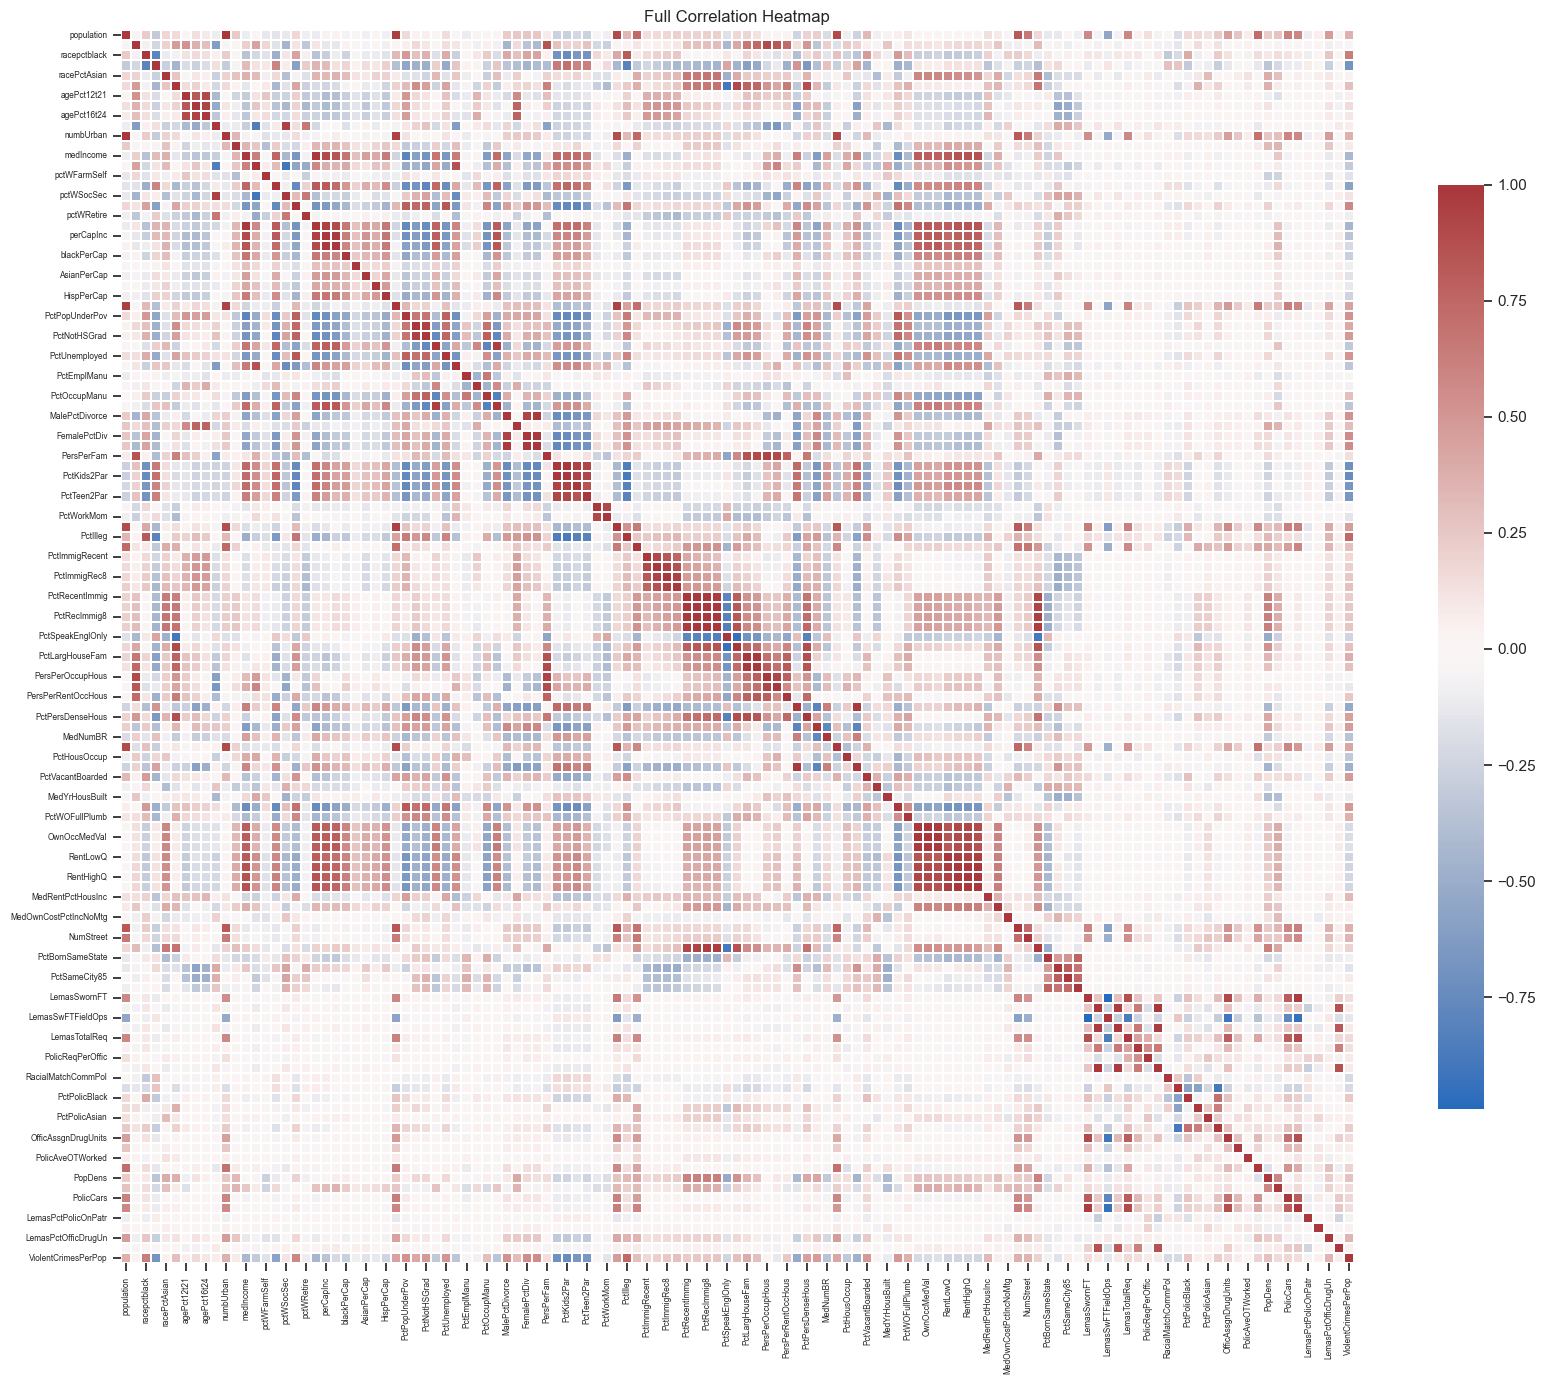

,ViolentCrimesPerPop
ViolentCrimesPerPop,1.000000
PctIlleg,0.737957
racepctblack,0.631264
pctWPubAsst,0.574665
FemalePctDiv,0.556032
TotalPctDiv,0.552777
MalePctDivorce,0.525407
PctPopUnderPov,0.521877
PctUnemployed,0.504235
PctHousNoPhone,0.488243


In [21]:
# Combine train and test only for descriptive plots, not for fitting models.
all_model_data = pd.concat([train_model_data, test_model_data], ignore_index=True)
correlations = all_model_data.corr()

fig, axis = plt.subplots(figsize=(18, 14))
sns.heatmap(
    correlations,
    cmap="vlag",
    center=0,
    linewidths=0.25,
    linecolor="white",
    square=True,
    cbar_kws={"shrink": 0.75},
    ax=axis,
)
axis.tick_params(axis="both", labelsize=6)
axis.set_title("Full Correlation Heatmap")
plt.tight_layout()
plt.show()

# A smaller table is easier to read than the full 123 by 123 matrix.
display(correlations.loc[[target_column], :].T.sort_values(target_column, ascending=False).head(12))


### (d) Calculate the Coefficient of Variation CV

In [22]:
# Coefficient of variation = standard deviation / mean.
cv_by_feature = (
    all_model_data.agg(["mean", "std"])
    .T.rename(columns={"mean": "mean", "std": "std"})
    .assign(cv=lambda frame: frame["std"] / frame["mean"].replace(0, np.nan))
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["cv"])
    .sort_values("cv", ascending=False)
)

display(cv_by_feature)

# sqrt(p) gives a manageable number of variables to visualize.
num_plot_features = int(np.sqrt(len(all_model_data.columns)))
high_cv_features = cv_by_feature.head(num_plot_features).index.tolist()
print(f"Using {num_plot_features} highest-CV variables for the exploratory plots:")
print(high_cv_features)

,mean,std,cv
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
...,...,...,...
NumKindsDrugsSeiz,0.552690,0.081172,0.146867
RacialMatchCommPol,0.683438,0.090637,0.132619
PctPolicWhite,0.725577,0.088443,0.121894
LemasPctPolicOnPatr,0.710740,0.085624,0.120471


Using 11 highest-CV variables for the exploratory plots:
['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


### (e) Scatter plots and box plots for highest CV features

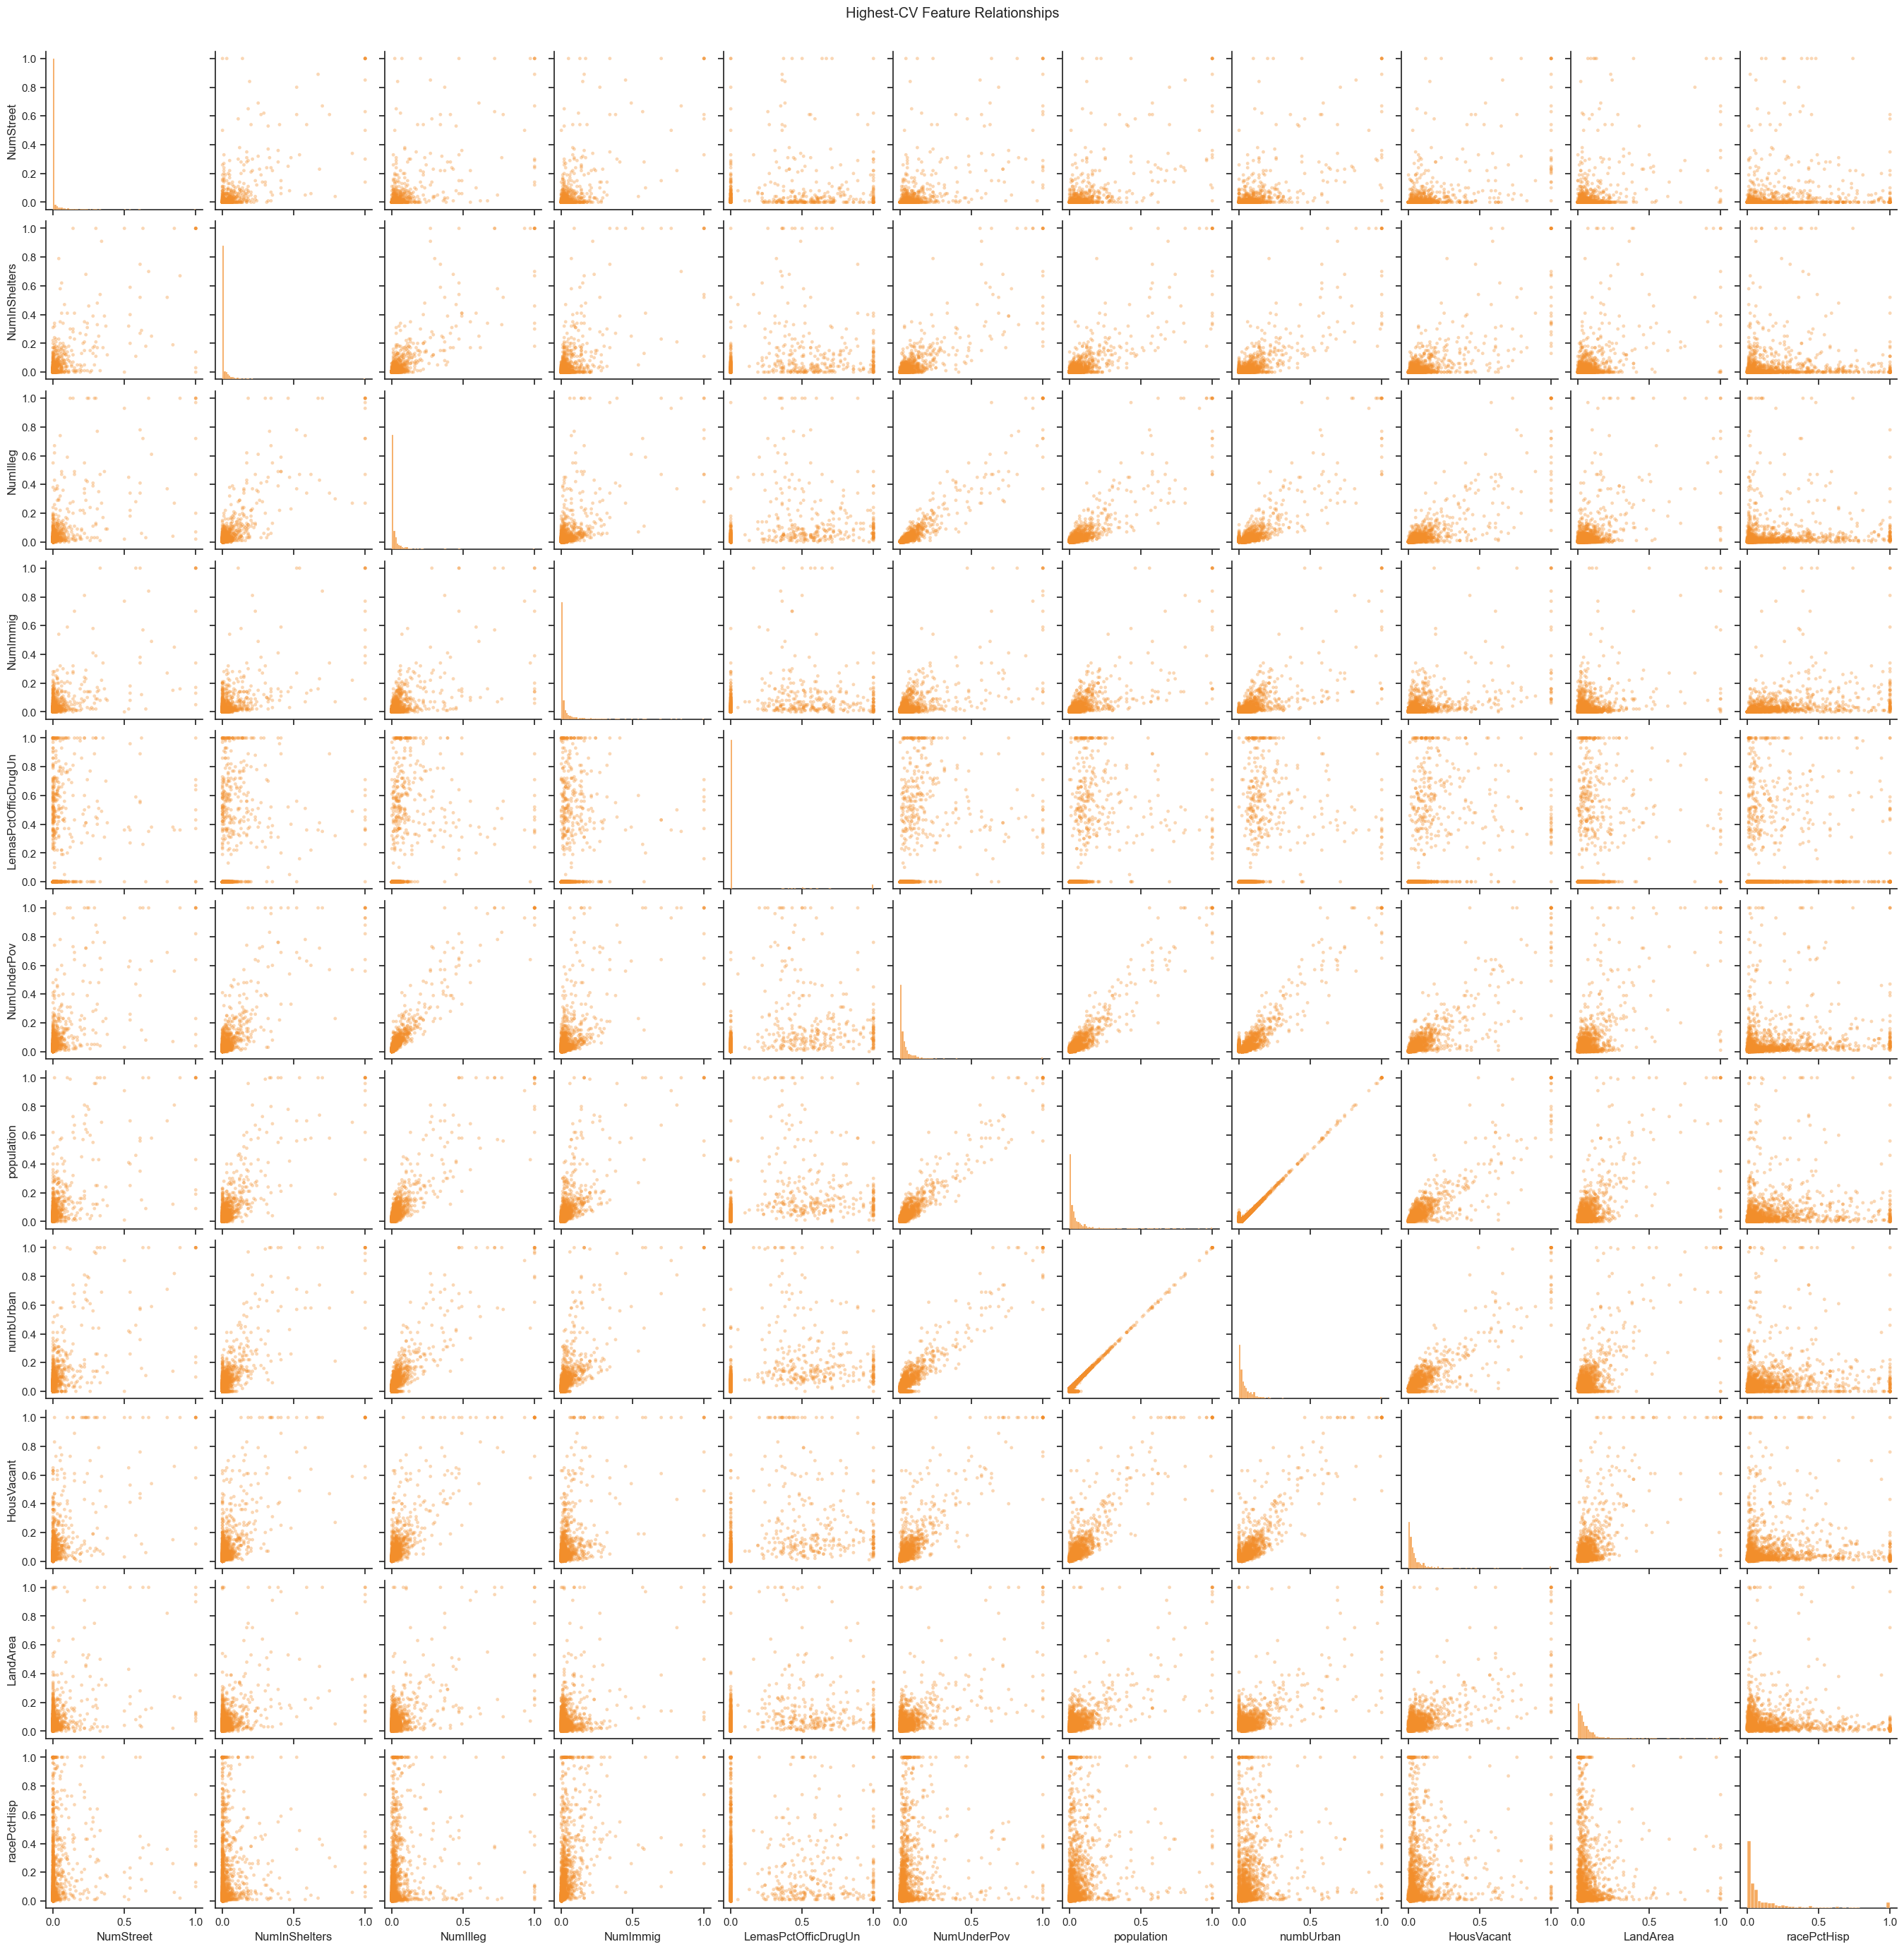

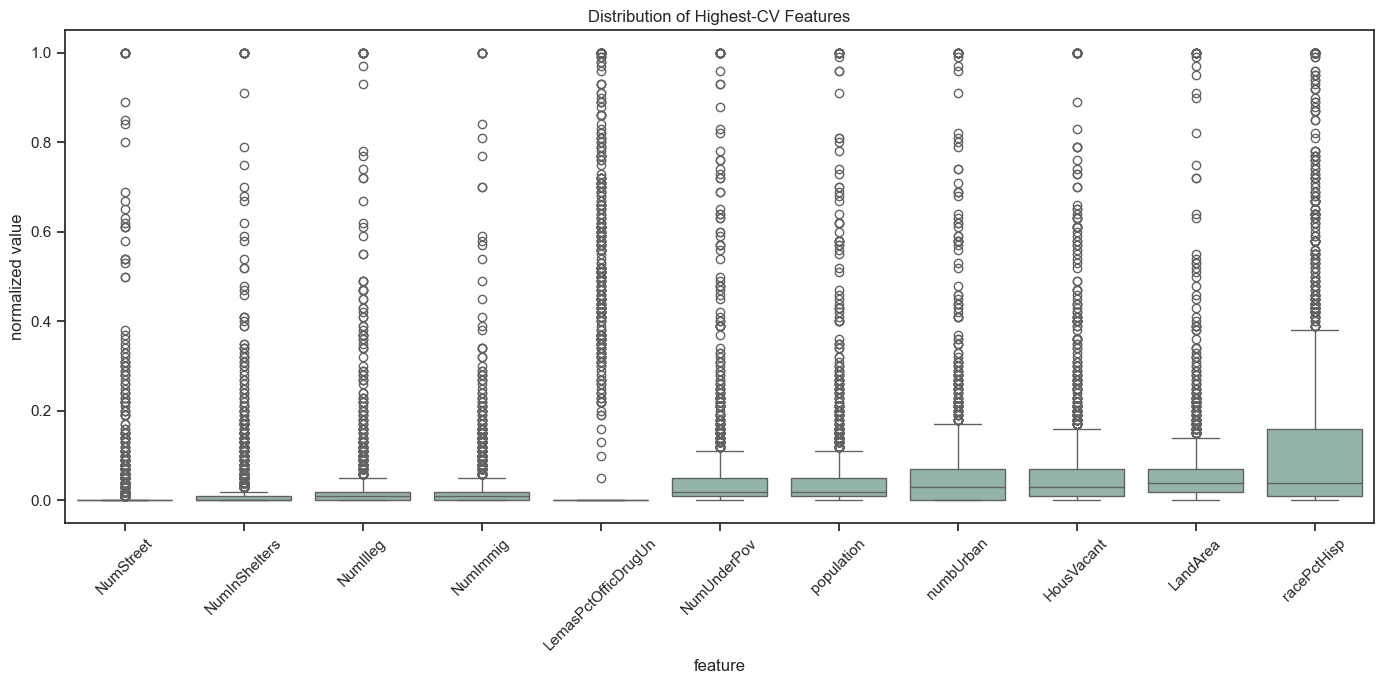

In [23]:
# Scatterplot matrix for the variables with the largest relative spread.
high_cv_data = all_model_data[high_cv_features]

pair_grid = sns.pairplot(
    high_cv_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 12, "edgecolor": "none", "color": "#f28e2b"},
    diag_kws={"color": "#f28e2b"},
)
pair_grid.fig.suptitle("Highest-CV Feature Relationships", y=1.01)
plt.show()

# Boxplots make the outliers/skewness easier to compare across these variables.
boxplot_data = high_cv_data.melt(var_name="feature", value_name="normalized value")
fig, axis = plt.subplots(figsize=(14, 7))
sns.boxplot(data=boxplot_data, x="feature", y="normalized value", color="#8fb9aa", ax=axis)
axis.tick_params(axis="x", rotation=45)
axis.set_title("Distribution of Highest-CV Features")
plt.tight_layout()
plt.show()


**Conclusion:** The highest-CV variables show large relative spread and many outliers, which is useful for exploratory screening. However, the scatter plots alone do not prove that these variables are statistically significant predictors of violent crime. Most relationships are noisy and clustered near zero, so significance should be judged through fitted models, cross-validation, and test error rather than visualization alone.

### (f) Fit a linear model

In [24]:
X_train = train_model_data[predictor_columns]
y_train = train_model_data[target_column]
X_test = test_model_data[predictor_columns]
y_test = test_model_data[target_column]

model_mse = {}

# statsmodels is useful here because it gives a classic linear regression fit.
ols_train = sm.add_constant(X_train, has_constant="add")
ols_test = sm.add_constant(X_test, has_constant="add")
ols_model = sm.OLS(y_train, ols_train).fit()
ols_predictions = ols_model.predict(ols_test)
model_mse["OLS"] = mean_squared_error(y_test, ols_predictions)

print(f"OLS test MSE: {model_mse['OLS']:.6f}")
display(
    ols_model.params.drop("const")
    .abs()
    .sort_values(ascending=False)
    .head(12)
    .to_frame("absolute coefficient")
)

OLS test MSE: 0.018142


,absolute coefficient
PctPersOwnOccup,0.870420
PctHousOwnOcc,0.748123
TotalPctDiv,0.667323
PolicOperBudg,0.647881
MalePctDivorce,0.518626
PersPerOccupHous,0.488645
OwnOccMedVal,0.480581
OwnOccLowQuart,0.394402
MedRent,0.381309
LemasTotalReq,0.347444


### (g) Fit a ridge regression model

In [25]:
# Ridge needs scaling because the penalty depends on coefficient size.
ridge_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": np.logspace(-3, 3, 25)},
    scoring="neg_mean_squared_error",
    cv=FIVE_FOLD,
)
ridge_search.fit(X_train, y_train)
model_mse["Ridge"] = mean_squared_error(y_test, ridge_search.predict(X_test))

ridge_results = pd.DataFrame(ridge_search.cv_results_)[["param_ridge__alpha", "mean_test_score"]]
ridge_results = ridge_results.rename(columns={"param_ridge__alpha": "alpha", "mean_test_score": "mean_cv_mse"})
ridge_results["mean_cv_mse"] = -ridge_results["mean_cv_mse"]

display(ridge_results.sort_values("mean_cv_mse"))
print(f"Selected ridge alpha: {ridge_search.best_params_['ridge__alpha']}")
print(f"Ridge test MSE: {model_mse['Ridge']:.6f}")

,alpha,mean_cv_mse
20,100.000000,0.019757
21,177.827941,0.019760
19,56.234133,0.019799
22,316.227766,0.019824
18,31.622777,0.019883
23,562.341325,0.019984
17,17.782794,0.020004
16,10.000000,0.020146
15,5.623413,0.020291
24,1000.000000,0.020305


Selected ridge alpha: 100.0
Ridge test MSE: 0.017508


### (h) Fit a LASSO model

In [26]:
# I fit LASSO twice: once on raw predictors and once after standardization.
lasso_models = {
    "LASSO raw": LassoCV(cv=10, random_state=SEED, max_iter=60000, n_jobs=-1),
    "LASSO scaled": make_pipeline(
        StandardScaler(),
        LassoCV(cv=10, random_state=SEED, max_iter=60000, n_jobs=-1),
    ),
}

lasso_rows = []
for label, estimator in lasso_models.items():
    estimator.fit(X_train, y_train)
    fitted_lasso = estimator.named_steps["lassocv"] if hasattr(estimator, "named_steps") else estimator
    selected = X_train.columns[np.abs(fitted_lasso.coef_) > 1e-8].tolist()
    model_mse[label] = mean_squared_error(y_test, estimator.predict(X_test))
    lasso_rows.append({
        "model": label,
        "alpha": fitted_lasso.alpha_,
        "test_mse": model_mse[label],
        "selected_feature_count": len(selected),
        "selected_features": selected,
    })

lasso_results = pd.DataFrame(lasso_rows)
display(lasso_results[["model", "alpha", "test_mse", "selected_feature_count"]])
for row in lasso_results.itertuples(index=False):
    print(f"{row.model} selected variables:")
    print(row.selected_features)

,model,alpha,test_mse,selected_feature_count
0,LASSO raw,0.000108,0.017771,77
1,LASSO scaled,0.000664,0.017839,76


LASSO raw selected variables:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameSt

**Comparison:** The raw and standardized LASSO models produce very similar test errors. In this run, the raw LASSO has a slightly lower test MSE, while the standardized LASSO selects one fewer variable. Because the Communities and Crime predictors are already normalized in the source data, standardization changes the result only slightly.

### (i) Fit a PCR model

,components,mean_cv_mse
59,60,0.020229
93,94,0.020243
94,95,0.020253
58,59,0.020267
95,96,0.020269
97,98,0.020295
56,57,0.020295
64,65,0.020304
96,97,0.020308
57,58,0.020308


Selected PCR components: 60
PCR test MSE: 0.018400


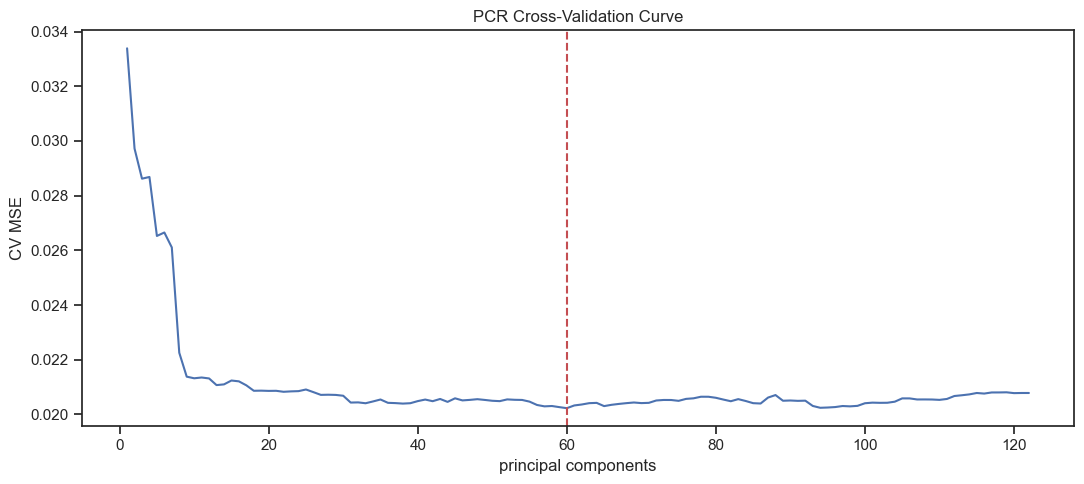

In [27]:
# Principal Components Regression: select the number of PCs by cross-validation.
pcr_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), PCA(), LinearRegression()),
    param_grid={"pca__n_components": list(range(1, X_train.shape[1] + 1))},
    scoring="neg_mean_squared_error",
    cv=FIVE_FOLD,
    n_jobs=-1,
)
pcr_search.fit(X_train, y_train)
model_mse["PCR"] = mean_squared_error(y_test, pcr_search.predict(X_test))

pcr_curve = pd.DataFrame(pcr_search.cv_results_)[["param_pca__n_components", "mean_test_score"]]
pcr_curve = pcr_curve.rename(columns={"param_pca__n_components": "components", "mean_test_score": "mean_cv_mse"})
pcr_curve["mean_cv_mse"] = -pcr_curve["mean_cv_mse"]
pcr_curve = pcr_curve.sort_values("components")

display(pcr_curve.sort_values("mean_cv_mse").head(15))
print(f"Selected PCR components: {pcr_search.best_params_['pca__n_components']}")
print(f"PCR test MSE: {model_mse['PCR']:.6f}")

fig, axis = plt.subplots(figsize=(11, 5))
axis.plot(pcr_curve["components"], pcr_curve["mean_cv_mse"], color="#4c72b0")
axis.axvline(pcr_search.best_params_["pca__n_components"], color="#c44e52", linestyle="--")
axis.set_xlabel("principal components")
axis.set_ylabel("CV MSE")
axis.set_title("PCR Cross-Validation Curve")
plt.tight_layout()
plt.show()

### (j) Fit a boosting tree

In [28]:
# Boosting. Use XGBoost if present; otherwise use sklearn's histogram gradient boosting.
if XGBRegressor is not None:
    boosting_base = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=175,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        random_state=SEED,
        n_jobs=1,
    )
    boosting_grid = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 5]}
    boosting_name = "XGBoost"
else:
    boosting_base = HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.04,
        max_leaf_nodes=15,
        random_state=SEED,
    )
    boosting_grid = {"l2_regularization": [0, 0.001, 0.01, 0.1, 1, 5]}
    boosting_name = "HistGradientBoostingRegressor"

boosting_search = GridSearchCV(
    estimator=boosting_base,
    param_grid=boosting_grid,
    scoring="neg_mean_squared_error",
    cv=FIVE_FOLD,
    n_jobs=1,
)
boosting_search.fit(X_train, y_train)
model_mse["Boosting"] = mean_squared_error(y_test, boosting_search.predict(X_test))

boosting_results = pd.DataFrame(boosting_search.cv_results_)
parameter_column = [name for name in boosting_results.columns if name.startswith("param_")][0]
boosting_results = boosting_results[[parameter_column, "mean_test_score"]].rename(
    columns={parameter_column: "regularization", "mean_test_score": "mean_cv_mse"}
)
boosting_results["mean_cv_mse"] = -boosting_results["mean_cv_mse"]

display(boosting_results.sort_values("mean_cv_mse"))
print(f"Boosting model used: {boosting_name}")
print(f"Best parameters: {boosting_search.best_params_}")
print(f"Boosting test MSE: {model_mse['Boosting']:.6f}")

# Final comparison table for all fitted regression methods.
display(pd.Series(model_mse, name="test_mse").sort_values().to_frame())

,regularization,mean_cv_mse
3,0.100,0.019932
2,0.010,0.020099
1,0.001,0.020100
4,1.000,0.020103
0,0.000,0.020175
5,5.000,0.020676


Boosting model used: XGBoost
Best parameters: {'reg_alpha': 0.1}
Boosting test MSE: 0.016150


,test_mse
Boosting,0.016150
Ridge,0.017508
LASSO raw,0.017771
LASSO scaled,0.017839
OLS,0.018142
PCR,0.018400


## References and Citations

- Czerniak, J., & Zarzycki, H. (2003). *Application of rough sets in the presumptive diagnosis of urinary system diseases*. Artificial Intelligence and Security in Computing Systems, ACS'2002 9th International Conference Proceedings, Kluwer Academic Publishers, 41-51.
- UCI Machine Learning Repository. (n.d.). *Acute Inflammations* [Dataset]. https://archive.ics.uci.edu/dataset/184/acute+inflammations
- UCI Machine Learning Repository. (n.d.). *Communities and Crime* [Dataset]. https://archive.ics.uci.edu/dataset/183/communities+and+crime
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830. https://scikit-learn.org/stable/
- Waskom, M. L. (2021). Seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://seaborn.pydata.org/
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://matplotlib.org/
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794. https://doi.org/10.1145/2939672.2939785
- XGBoost Developers. (n.d.). *XGBoost Python package documentation*. https://xgboost.readthedocs.io/

## AI Assistance Disclosure

OpenAI ChatGPT/Codex was used as a coding and editing assistant for this notebook. Assistance included debugging the Python environment, revising visualization code, improving plot readability, and drafting reference/disclosure text. The submitted analysis, code, model choices, outputs, and interpretations remain my responsibility.
